### Build the LLaVA repository locally
DO NOT RUN IF REPO HAS ALREADY BEEN CLONED

In [ ]:
# !git clone https://github.com/haotian-liu/LLaVA.git /content/drive/MyDrive/Best\ Lies\ Are\ Half\ Truths\ \|\ Project/Code/llava_guided_inpaint/LLaVA

Cloning into '/content/drive/MyDrive/Best Lies Are Half Truths | Project/Code/llava_guided_inpaint/LLaVA'...
remote: Enumerating objects: 2247, done.
remote: Total 2247 (delta 0), reused 0 (delta 0), pack-reused 2247
Receiving objects: 100% (2247/2247), 13.89 MiB | 13.31 MiB/s, done.
Resolving deltas: 100% (1402/1402), done.
Updating files: 100% (175/175), done.


### Dependancies

In [ ]:
!pip install --upgrade pip
!pip install -e LlaVa/

Obtaining file:///raid/mphute6/HalfTruths/LlaVa
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for llava (pyproject.toml) ... done
  Created wheel for llava: filename=llava-1.2.2.post1-0.editable-py3-none-any.whl size=17198 sha256=fd7830cfe04a3b058c89c97899148b8df5989460c1ab39e67ee752f15a348f8e
  Stored in directory: /tmp/pip-ephem-wheel-cache-9bao2e87/wheels/63/ef/d2/36786fea032f98aedc7163c9a02fbd800a2085a115c1373202
Successfully built llava
  Attempting uninstall: llava
    Found existing installation: llava 1.2.2.post1
    Uninstalling llava-1.2.2.post1:
      Successfully uninstalled llava-1.2.2.post1


In [ ]:
!pip install transformers sentence_transformers datasets

In [ ]:
import sys
# sys.path.append('/content/drive/MyDrive/Best Lies Are Half Truths | Project/Code/llava_guided_inpaint/')
sys.path.append("/raid/mphute6/HalfTruths/LlaVa")
sys.path.append('/raid/mphute6/HalfTruths/LlaVa/llava/')
sys.path.append('/raid/mphute6/HalfTruths/LlaVa/llava/eval')
sys.path.append('/raid/mphute6/HalfTruths/LlaVa/llava/eval/run_llava')

from tqdm.notebook import tqdm
from run_llava import eval_model, load_model, eval_model_wo_loading
# from run_llava import *
from sentence_transformers import SentenceTransformer, util
from datasets import load_dataset
from PIL import Image
import random
import os
import json

/home/mphute6/miniconda3/envs/llava/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# SANDBOX --
This section was used to explore different ways that we can:

1. prompt LLaVA for mask perturbation recommendations
2. create the image augmentations pipeline with LLaVA's outputs

**Later sections of this notebook are devoted to visualizing LLaVA's outputs with different outputs and configurations!**




## Model Variables & Data Paths

In [ ]:
######
# set this variable according to path where llava weights have been downloaded and the directory where to cache
LLAVA_PATH = "liuhaotian/llava-v1.6-mistral-7b"
CACHE_DIR = "/raid/mphute6/cache"
DATA_DIR = "/raid/mphute6/HalfTruths/Half_Truths_Dataset_SAMPLE"
ROOT_DIR = "/raid/mphute6/HalfTruths/"
######

# Loading dataset metadata:
with open(os.path.join(DATA_DIR, "metadata.json"), "r") as f:
    metadata = json.load(f)

# LLaVA model agruments:
model_path = LLAVA_PATH
prompt = ""
image_file = ""
args = type('Args', (), {
    "model_path": model_path,
    "model_base": None,
    "model_name": "LlavaLlamaForCausalLM",
    "query": prompt,
    "conv_mode": None,
    "image_file": image_file,
    "sep": ",",
    "temperature": 0.5,
    "top_p": 0.5,
    "num_beams": 5,
    "max_new_tokens": 1024 ,
    "cache_dir" : CACHE_DIR
})()

### Load LLaVA Model

In [ ]:
tokenizer, model, image_processor, context_len = load_model(args)

tokenizer_config.json: 100%|██████████| 1.46k/1.46k [00:00<00:00, 9.46MB/s]
tokenizer.model: 100%|██████████| 493k/493k [00:00<00:00, 54.6MB/s]
special_tokens_map.json: 100%|██████████| 438/438 [00:00<00:00, 2.35MB/s]
tokenizer.json: 100%|██████████| 1.80M/1.80M [00:00<00:00, 3.29MB/s]
config.json: 100%|██████████| 1.63k/1.63k [00:00<00:00, 10.3MB/s]
You are using a model of type llava_mistral to instantiate a model of type llava_llama. This is not supported for all configurations of models and can yield errors.
model.safetensors.index.json: 100%|██████████| 73.2k/73.2k [00:00<00:00, 185MB/s]
model-00001-of-00004.safetensors: 100%|██████████| 4.94G/4.94G [00:44<00:00, 110MB/s]
model-00002-of-00004.safetensors: 100%|██████████| 5.00G/5.00G [00:46<00:00, 107MB/s]
model-00003-of-00004.safetensors: 100%|██████████| 4.93G/4.93G [00:45<00:00, 108MB/s]
model-00004-of-00004.safetensors: 100%|██████████| 262M/262M [00:02<00:00, 115MB/s]
/home/mphute6/miniconda3/envs/llava/lib/python3.10/site-pa

### Mask Label Perturbation Helper Functions

**Notes:**
- prompts that request "replacement" suggestions work great with scene images and images of objects, but not much with people.
- I created a prompt struture that requests an augmentation of the provided mask, which works substantially better of human attributes.
- I think we should change which prompt we use based on the what dataset we are working with.

In [ ]:
# prompt context:

context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications that may affect the perception or interpretation of the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

output_struct = """

Return your answer as a JSON object, where the key is the semantic change type and the value contains the recommended change."""

In [ ]:
# we need a "taxonomy" of prompts to use for both the inpainting & p2p perturbations:

# small_sem_change = "the change is subtle and realistic in context of the image"
# medium_sem_change = "the change is noticable but is realistic in context of the image"
# large_sem_change = "the change makes the image look suprising or strange to an audience"

small_sem_change = "small"
medium_sem_change = "medium"
large_sem_change = "large"


def size_based_change(img_path, mask, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choices(prompt_types, weights=(aug_p*100, (1-aug_p)*100), k=1)[0]
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a small, medium and large semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible. {output_struct}"

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a small, medium and large semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible. {output_struct}"
        # prompt = f"What is I can replace the {mask} with in the image, such that {sem_change_str}? Your recommendation must be of a similar size and structure to the {mask}. Provide the name of the object, use as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)


## Semantic Label Perturbation Helper Functions

**Notes:**


In [ ]:
# prompt context:

context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Could be something like changing the color of a specific object, or adding or removing a minor detail, adjusting the composition or perspective of the image, or changing the distance or angle with which the image is taken, or slightly adjusting the color distribution of the image. This change would not significantly alter the overall meaning or context of the image.
2. Medium Semantic Change: Could involve moving an object or person to a different location within the frame, or changing the emotions of the people in the frame. Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: This could include adding or removing major elements of the image, such as people, objects, or landmarks, or making fundamental changes to the image's color scheme, lighting, or other visual elements. Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

output_struct = """

Return the captions in the format:
Original Caption:

Modified Caption 1:
Change 1:

Modified Caption 2:
Change 2:
"""

In [ ]:
# we need a "taxonomy" of prompts to use for both the inpainting & p2p perturbations:

# small_sem_change = "the change is subtle and realistic in context of the image"
# medium_sem_change = "the change is noticable but is realistic in context of the image"
# large_sem_change = "the change makes the image look suprising or strange to an audience"

small_sem_change = "small"
medium_sem_change = "medium"
large_sem_change = "large"


def semantics_based_change(img_path, size):

    prompt = context +  f"Write a detailed caption for the image. Give me 5 unique {size} changes I can make to the original caption." + output_struct

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)


## Semantics Sandbox

In [ ]:
img_ids = list(metadata.keys())
exp_id = random.choice(img_ids)
exp_img_meta = metadata[exp_id]

exp_img_meta


{'entities': ['road',
  'ego vehicle',
  'building',
  'vegetation',
  'out of roi',
  'car',
  'sidewalk',
  'sky',
  'pole'],
 'class': ['road', 'building', 'ego vehicle'],
 'dataset': 'CityScapes',
 'objects': [{'id': 'erfurt_000020_000019_instance000',
   'mask_path': 'Half_Truths_Dataset/masks/CityScapes/erfurt_000020_000019_instance000.png',
   'name': 'sky',
   'ratio': 0.40804290771484375},
  {'id': 'erfurt_000020_000019_instance001',
   'mask_path': 'Half_Truths_Dataset/masks/CityScapes/erfurt_000020_000019_instance001.png',
   'name': 'road',
   'ratio': 0.546875},
  {'id': 'erfurt_000020_000019_instance002',
   'mask_path': 'Half_Truths_Dataset/masks/CityScapes/erfurt_000020_000019_instance002.png',
   'name': 'building',
   'ratio': 0.013866424560546875},
  {'id': 'erfurt_000020_000019_instance003',
   'mask_path': 'Half_Truths_Dataset/masks/CityScapes/erfurt_000020_000019_instance003.png',
   'name': 'vegetation',
   'ratio': 0.005863189697265625},
  {'id': 'erfurt_000020_

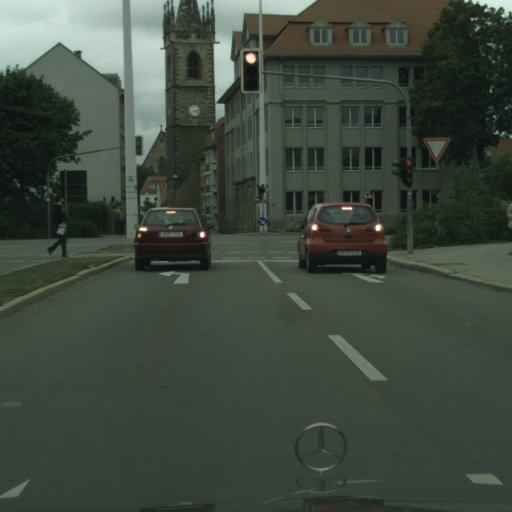

In [ ]:
im = Image.open(os.path.join(ROOT_DIR, exp_img_meta["image_path"]))
display(im)

In [ ]:
image_file = os.path.join(ROOT_DIR, exp_img_meta["image_path"])
semantics_based_change(image_file, "small")

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


'Original Caption:\nIn a bustling city, two cars are stopped at a red traffic light. The scene captures the everyday hustle and bustle of urban life.\n\nModified Caption 1:\nIn a quiet city, two cars are stopped at a red traffic light. The scene captures the calm and serene atmosphere of urban life.\n\nChange 1:\nThe word "bustling" is replaced with "quiet."\n\nModified Caption 2:\nIn a busy city, two cars are stopped at a red traffic light. The scene captures the hectic and fast-paced nature of urban life.\n\nChange 2:\nThe word "bustling" is replaced with "busy."\n\nModified Caption 3:\nIn a lively city, two cars are stopped at a red traffic light. The scene captures the vibrant and energetic atmosphere of urban life.\n\nChange 3:\nThe word "lively" is replaced with "vibrant."\n\nModified Caption 4:\nIn a vibrant city, two cars are stopped at a red traffic light. The scene captures the colorful and dynamic nature of urban life.\n\nChange 4:\nThe word "vibrant" is replaced with "color

In [ ]:
image_file = os.path.join(ROOT_DIR, exp_img_meta["image_path"])
semantics_based_change(image_file, "medium")

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


'```json\n{\n  "small": "In the image, two cars are stopped at a red traffic light on a city street. The scene captures the everyday hustle and bustle of urban life.",\n  "medium": [\n    "In the image, two cars are stopped at a red traffic light on a city street. The scene captures the everyday hustle and bustle of urban life, but with a twist: one of the cars is actually a self-driving vehicle.",\n    "In the image, two cars are stopped at a red traffic light on a city street. The scene captures the everyday hustle and bustle of urban life, but with a twist: one of the cars is a classic Mercedes-Benz.",\n    "In the image, two cars are stopped at a red traffic light on a city street. The scene captures the everyday hustle and bustle of urban life, but with a twist: one of the cars is a modern electric vehicle.",\n    "In the image, two cars are stopped at a red traffic light on a city street. The scene captures the everyday hustle and bustle of urban life, but with a twist: one of th

In [ ]:
image_file = os.path.join(ROOT_DIR, exp_img_meta["image_path"])
semantics_based_change(image_file, "large")

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


'Original Caption:\nIn a bustling city, two cars are stopped at a red traffic light. The cars are positioned in the middle of the street, waiting for the light to change. The scene is set against a backdrop of a large building with a clock tower.\n\nModified Caption 1:\nIn a bustling city, two cars are stopped at a red traffic light. The cars are positioned in the middle of the street, waiting for the light to change. The scene is set against a backdrop of a large building with a clock tower. Change 1: The cars are now red and black, adding a pop of color to the scene.\n\nModified Caption 2:\nIn a bustling city, two cars are stopped at a red traffic light. The cars are positioned in the middle of the street, waiting for the light to change. The scene is set against a backdrop of a large building with a clock tower. Change 2: The cars are now red and black, adding a pop of color to the scene. Change 2: The building in the background now has a large, colorful mural on its side, adding a 

## Sandbox

Exploring LLaVA-Mistral's ability to propose mask label perturbations:

In [ ]:
# checking for duplicate mask ids for an org image in dataset:

ds_w_same_mid = []

for k, v in metadata.items():
    obj_ids = []
    for obj in v["objects"]:
        obj_ids.append(obj["id"])

    try:
        if obj_ids[0] == obj_ids[1]:
            if v['dataset'] not in ds_w_same_mid:
                ds_w_same_mid.append(v['dataset'])
    except IndexError:
        pass

ds_w_same_mid

['CelebA-HQ']

In [ ]:
# randomly selecting example from data:

img_ids = list(metadata.keys())
exp_id = random.choice(img_ids)
exp_img_meta = metadata[exp_id]

exp_img_meta

{'entities': ['skateboard'],
 'class': 'skateboard',
 'dataset': 'OpenImages',
 'objects': [{'id': 'd43a7f1c16186190_m06_fw_8b6acc43',
   'mask_path': 'Half_Truths_Dataset/masks/OpenImages/d43a7f1c16186190_m06_fw_8b6acc43.png',
   'name': 'skateboard',
   'ratio': 0.023799896240234375}],
 'image_path': 'Half_Truths_Dataset_SAMPLE/images/OpenImages/d43a7f1c16186190.jpg'}

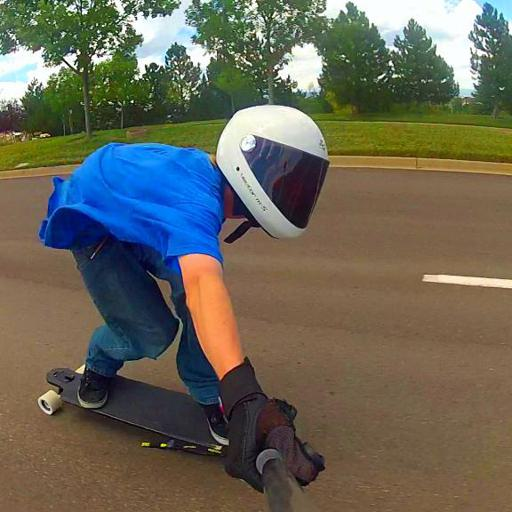

In [ ]:
# visualize selected example:

im = Image.open(os.path.join(ROOT_DIR, exp_img_meta["image_path"]))
display(im)

In [ ]:
mask = "skateboard"
image_file = os.path.join(ROOT_DIR, exp_img_meta["image_path"])
size_based_change(image_file, mask)

replace


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


'```json\n{\n  "small": "Replace the skateboard with a bicycle",\n  "medium": "Replace the skateboard with a scooter",\n  "large": "Replace the skateboard with a motorcycle"\n}\n```'

## Analysis of LLaVA Training Data

# LLaVA Prompting Technique Investigation

This section visualizes recommended mask perturbations created by LLaVA subject to:
1. Various text encoders
2. Various prompt structures

This exploration will aid us in determining what kind of prompt structure would be best for us to use. All models explored in this notebook were drawn from: https://github.com/haotian-liu/LLaVA/blob/main/docs/MODEL_ZOO.md

### Helper Functions

In [ ]:
# prompt: create a function that visualizes a set of 6 images using matplotlib, create titles, x and y labels for each image, use fig and axes

import matplotlib.pyplot as plt

def sample_data(metadata):
    """
    Samples 6 images randomly from the Half-Truths Input Data.
    Returns the sample as a dictionary.
    """
    img_ids = list(metadata.keys())
    exp_id = random.choices(img_ids, k=6)
    data_samp = {}

    for id_ in exp_id:
        info = metadata[id_]
        info["object"] = random.choice(info["objects"])
        del info["objects"]
        data_samp[id_] = info

    return data_samp


def clean_json_output(output):
    """
    Cleans the model's JSON object output into something that
    will be read by json.loads.

    Return json object.
    """

    if "`" in output or 'json' in output:
        output = output[output.find('{'):output.rfind('}')+1]
        output = output.replace("`", "")
    output = output.replace("\n", "").replace("\\", "")

    return json.loads(output)


def visualize_images(data_samp, figsize=(15, 15), suptitle=None):
  """
  This function visualizes a set of 6 images using matplotlib.
  """

  fig, axes = plt.subplots(2, 3, figsize=figsize, constrained_layout=True)
  ids = list(data_samp.keys())
  if suptitle:
    fig.suptitle(suptitle, fontsize=12, fontweight="bold")

  for i, ax in enumerate(axes.flat):

    image_info = data_samp[ids[i]]

    target_str = image_info["object"]["target"]
    title_ = f"Recommended Change(s):\n{target_str}"
    image_ = Image.open(os.path.join(ROOT_DIR, image_info["image_path"]))
    mask_name = image_info["object"]["name"]

    ax.imshow(image_)
    ax.set_title(title_, fontsize=10)
    ax.set_xlabel(f"Mask: {mask_name}", fontweight="bold")
    ax.set_ylabel(f"Dataset: {image_info['dataset']}", fontweight="bold")
    ax.set(xticklabels=[])
    ax.set(yticklabels=[])
    ax.tick_params(axis='both', which='both', length=0)

  plt.tight_layout()
  plt.show()



### Data Loading

In [ ]:
######
# set this variable according to path where llava weights have been downloaded and the directory where to cache
CACHE_DIR = "/content/drive/MyDrive/Best Lies Are Half Truths | Project/Code/llava_guided_inpaint/cache"
DATA_DIR = "/content/drive/MyDrive/Best Lies Are Half Truths | Project/Data/Half_Truths_Dataset_SAMPLE"
ROOT_DIR = "/content/drive/MyDrive/Best Lies Are Half Truths | Project/Data/"
######

# Loading dataset metadata:
with open(os.path.join(DATA_DIR, "metadata.json"), "r") as f:
    metadata = json.load(f)

### Sample some data from Half-Truths Input Data:

In [ ]:
data_samp = sample_data(metadata)
data_samp.keys()

dict_keys(['bochum_000000_034936', 'bremen_000201_000019', 'ADE_train_00012402', 'e7987b6c9fb372bc', 'ADE_train_00012530', '4ff2306dab883e42'])

# Exploring Different Prompting Techniques w/ LLaVA 1.6 & Mistral 7B Text Encoder

### Loading Model:

In [ ]:
# LLaVA model agruments for LLaVA-Mistral:
model_path = "liuhaotian/llava-v1.6-mistral-7b"
prompt = ""
image_file = ""
args = type('Args', (), {
    "model_path": model_path,
    "model_base": None,
    "model_name": "LlavaLlamaForCausalLM",
    "query": prompt,
    "conv_mode": None,
    "image_file": image_file,
    "sep": ",",
    "temperature": 0.5,
    "top_p": 0.5,
    "num_beams": 5,
    "max_new_tokens": 1024 ,
    "cache_dir" : CACHE_DIR
})()

tokenizer, model, image_processor, context_len = load_model(args)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:88: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/1.46k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/438 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

...

pytorch_model.bin:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
/usr/local/lib/python3.10/dist-packages/torch/nn/modules/module.py:2025: UserWarning: for vision_model.embeddings.class_embedding: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(f'for {key}: copying from a non-meta parameter in the checkpoint to a meta '
/usr/local/lib/python3.10/dist-packages/torch/nn/modules/module.py:2025: UserWarning: for vision_model.embeddings.patch_

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacty of 14.75 GiB of which 5.06 MiB is free. Process 12764 has 14.74 GiB memory in use. Of the allocated memory 14.51 GiB is allocated by PyTorch, and 138.56 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

## Context, Output Struct, 3 Recommendations:

In [ ]:
# prompt context:

context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications to the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

output_struct = """

Return your answer as a JSON object, where the key is the semantic change type and the value contains the recommended change."""

In [ ]:
def get_llava_perts(data_samp):
    """
    Uses the latest instantiation of the ``size_based_change`` function
    to generate recommended perturbations for a set of images using LLaVA.

    The recommended perturbation is saved in the ``data_samp`` dictionary,
    under the key ``target``.
    """

    for id_, info in data_samp.items():

        mask = info["object"]["name"]
        image_file = os.path.join(ROOT_DIR, info["image_path"])
        output = size_based_change(image_file, mask)

        if '{' in output:
            structured = False
            while not structured:
                try:
                    target = clean_json_output(output)
                    structured = True
                except:
                    continue

            target_str = ""
            for k, v in target.items():
                target_str += f"{k}: {v}\n"
            output = target_str[:-2]


        info["object"]["target"] = output
        data_samp[id_] = info

    return data_samp


def size_based_change(img_path, mask, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choice(prompt_types)
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a small, medium and large semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible. {output_struct}"

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a small, medium and large semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible. {output_struct}"
        # prompt = f"What is I can replace the {mask} with in the image, such that {sem_change_str}? Your recommendation must be of a similar size and structure to the {mask}. Provide the name of the object, use as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)

In [ ]:
# getting llava recommended changes:
data_samp_processed = get_llava_perts(data_samp)

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


replace


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


replace


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


...

aug


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


replace


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


aug


<ipython-input-59-d4ec739af21b>:65: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


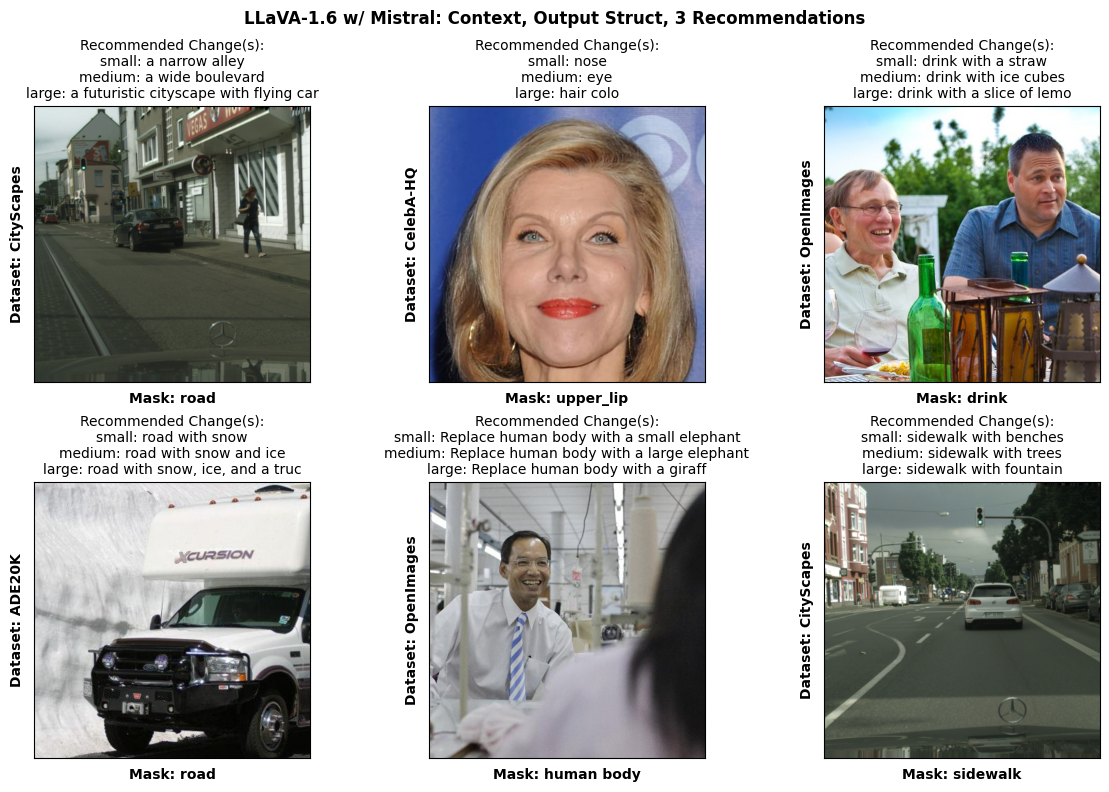

In [ ]:
title = "LLaVA-1.6 w/ Mistral: Context, Output Struct, 3 Recommendations"
visualize_images(data_samp, figsize=(12, 8), suptitle=title)

## Context, 1 Recommendations based on STR Input:

In [ ]:
context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications to the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

In [ ]:
def get_llava_perts(data_samp):
    """
    Uses the latest instantiation of the ``size_based_change`` function
    to generate recommended perturbations for a set of images using LLaVA.

    The recommended perturbation is saved in the ``data_samp`` dictionary,
    under the key ``target``.
    """

    for id_, info in data_samp.items():

        mask = info["object"]["name"]
        image_file = os.path.join(ROOT_DIR, info["image_path"])
        try:
            output = size_based_change(image_file, mask)
            mag_change = None
        except:
            mag_change = random.choice(["small", "medium", "large"])
            output = size_based_change(image_file, mask, mag_change)

        if '{' in output:
            structured = False
            while not structured:
                try:
                    target = clean_json_output(output)
                    structured = True
                except:
                    continue

            target_str = ""
            for k, v in target.items():
                target_str += f"{k}: {v}\n"
            output = target_str[:-2]

        elif mag_change is not None:
            output = f"Magnitude: {mag_change} semantic change\n{output}"

        info["object"]["target"] = output
        data_samp[id_] = info

    return data_samp


def size_based_change(img_path, mask, mag_change, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choice(prompt_types)
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a {mag_change} semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible."

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a {mag_change} semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)

In [ ]:
# getting llava recommended changes:
data_samp_processed = get_llava_perts(data_samp)

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


aug


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


aug


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


...

aug


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


aug


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


aug


<ipython-input-55-0413d8872301>:65: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


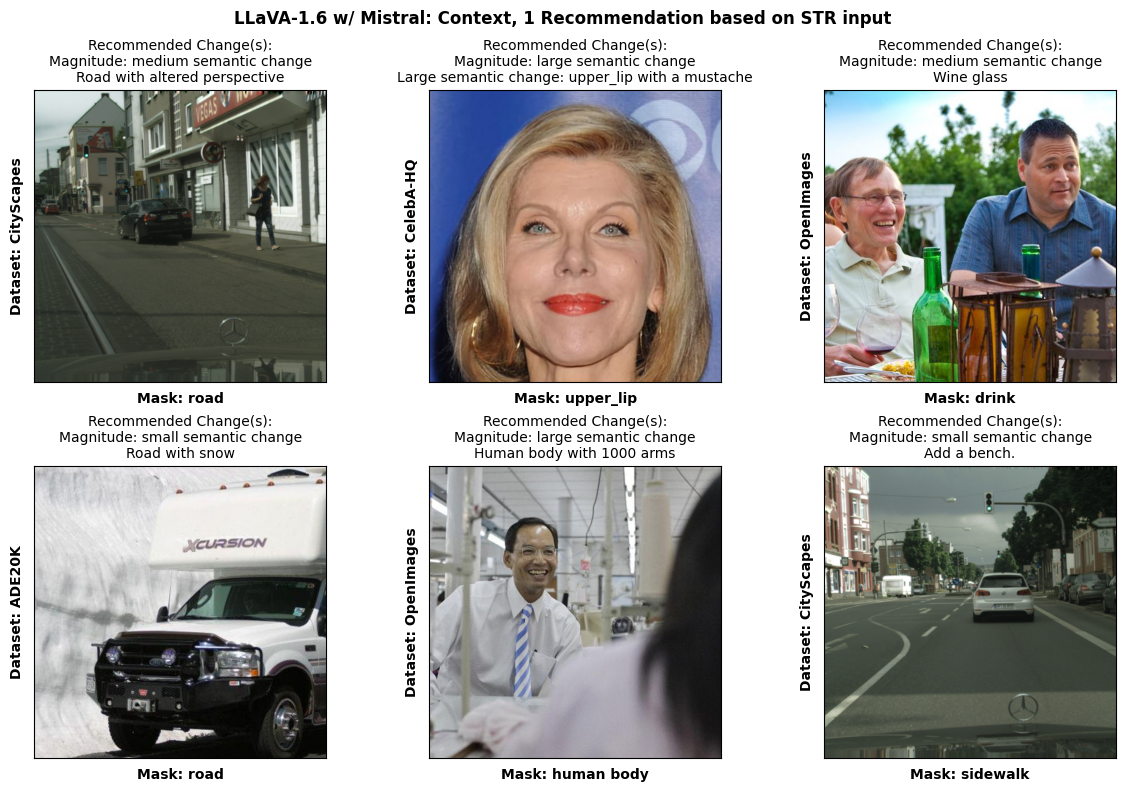

In [ ]:
title = "LLaVA-1.6 w/ Mistral: Context, 1 Recommendation based on STR input"
visualize_images(data_samp, figsize=(12, 8), suptitle=title)

# Exploring Different Prompting Techniques w/ LLaVA 1.5 & Vicuna 7B Text Encoder

In [ ]:
# LLaVA model agruments for LLaVA-Mistral:
model_path = "liuhaotian/llava-v1.5-7b"
prompt = ""
image_file = ""
args = type('Args', (), {
    "model_path": model_path,
    "model_base": None,
    "model_name": "LlavaLlamaForCausalLM",
    "query": prompt,
    "conv_mode": None,
    "image_file": image_file,
    "sep": ",",
    "temperature": 0.5,
    "top_p": 0.5,
    "num_beams": 5,
    "max_new_tokens": 1024 ,
    "cache_dir" : CACHE_DIR
})()

tokenizer, model, image_processor, context_len = load_model(args)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:88: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
You are using a model of type llava to instantiate a model of type llava_llama. This is not supported for all configurations of models and can yield errors.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## Context, Output Struct, 3 Recommendations:

In [ ]:
!pip install ipdb -q

In [ ]:
import ipdb

In [ ]:
# prompt context:

context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications to the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

output_struct = """

Return your answer as a JSON object, where the key is the semantic change type and the value contains the recommended change."""

In [ ]:
def get_llava_perts(data_samp):
    """
    Uses the latest instantiation of the ``size_based_change`` function
    to generate recommended perturbations for a set of images using LLaVA.

    The recommended perturbation is saved in the ``data_samp`` dictionary,
    under the key ``target``.
    """

    for id_, info in data_samp.items():

        mask = info["object"]["name"]
        image_file = os.path.join(ROOT_DIR, info["image_path"])
        output = size_based_change(image_file, mask)

        if '{' in output:
            try:
                target = clean_json_output(output)
            except:
                ipdb.set_trace()

            target_str = ""
            for k, v in target.items():
                target_str += f"{k}: {v}\n"
            output = target_str[:-2]


        info["object"]["target"] = output
        data_samp[id_] = info

    return data_samp


def size_based_change(img_path, mask, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choice(prompt_types)
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a small, medium and large semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible. {output_struct}"

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a small, medium and large semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible. {output_struct}"
        # prompt = f"What is I can replace the {mask} with in the image, such that {sem_change_str}? Your recommendation must be of a similar size and structure to the {mask}. Provide the name of the object, use as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)

In [ ]:
# getting llava recommended changes:
data_samp_processed = get_llava_perts(data_samp)

aug
aug
replace
aug
replace
replace


<ipython-input-3-f3d214da4c6b>:66: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


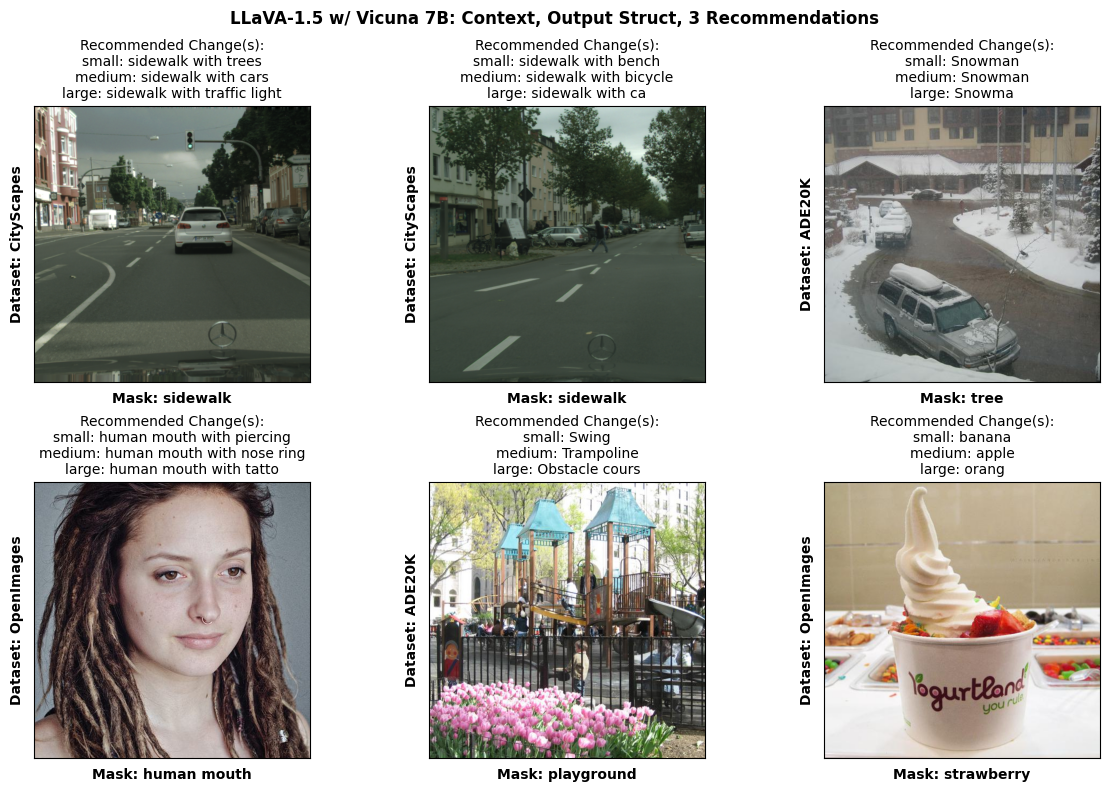

In [ ]:
title = "LLaVA-1.5 w/ Vicuna 7B: Context, Output Struct, 3 Recommendations"
visualize_images(data_samp, figsize=(12, 8), suptitle=title)

## Context, 1 Recommendations based on STR Input:

In [ ]:
context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications to the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

In [ ]:
def get_llava_perts(data_samp):
    """
    Uses the latest instantiation of the ``size_based_change`` function
    to generate recommended perturbations for a set of images using LLaVA.

    The recommended perturbation is saved in the ``data_samp`` dictionary,
    under the key ``target``.
    """

    for id_, info in data_samp.items():

        mask = info["object"]["name"]
        image_file = os.path.join(ROOT_DIR, info["image_path"])
        try:
            output = size_based_change(image_file, mask)
            mag_change = None
        except:
            mag_change = random.choice(["small", "medium", "large"])
            output = size_based_change(image_file, mask, mag_change)

        if '{' in output:
            structured = False
            while not structured:
                try:
                    target = clean_json_output(output)
                    structured = True
                except:
                    continue

            target_str = ""
            for k, v in target.items():
                target_str += f"{k}: {v}\n"
            output = target_str[:-2]

        elif mag_change is not None:
            output = f"Magnitude: {mag_change} semantic change\n{output}"

        info["object"]["target"] = output
        data_samp[id_] = info

    return data_samp


def size_based_change(img_path, mask, mag_change, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choice(prompt_types)
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a {mag_change} semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible."

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a {mag_change} semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)

In [ ]:
# getting llava recommended changes:
data_samp_processed = get_llava_perts(data_samp)

replace
aug
aug
replace
aug
aug


<ipython-input-3-f3d214da4c6b>:66: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


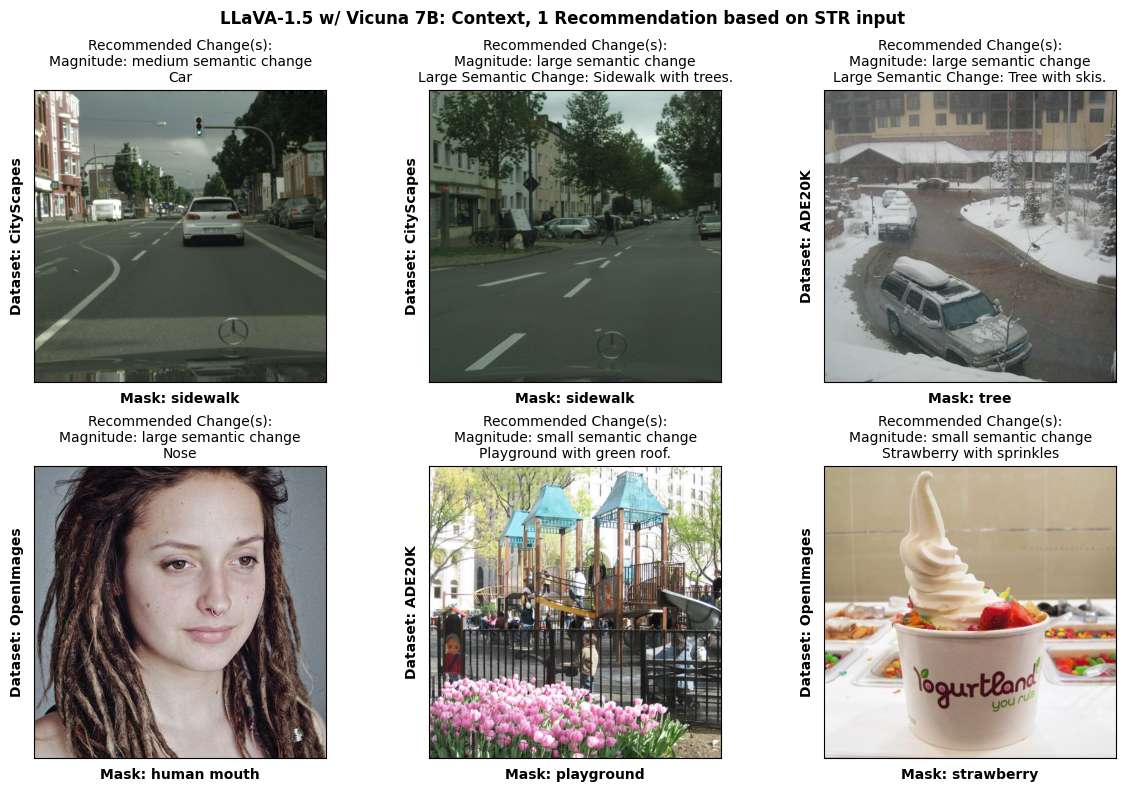

In [ ]:
title = "LLaVA-1.5 w/ Vicuna 7B: Context, 1 Recommendation based on STR input"
visualize_images(data_samp, figsize=(12, 8), suptitle=title)

# Exploring Different Prompting Techniques w/ LLaVA 1.5 & Vicuna 13B Text Encoder

In [ ]:
# LLaVA model agruments for LLaVA-Mistral:
model_path = "liuhaotian/llava-v1.5-13b"
prompt = ""
image_file = ""
args = type('Args', (), {
    "model_path": model_path,
    "model_base": None,
    "model_name": "LlavaLlamaForCausalLM",
    "query": prompt,
    "conv_mode": None,
    "image_file": image_file,
    "sep": ",",
    "temperature": 0.5,
    "top_p": 0.5,
    "num_beams": 5,
    "max_new_tokens": 1024 ,
    "cache_dir" : CACHE_DIR
})()

tokenizer, model, image_processor, context_len = load_model(args)

## Context, Output Struct, 3 Recommendations:

In [ ]:
!pip install ipdb -q

In [ ]:
import ipdb

In [ ]:
# prompt context:

context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications to the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

output_struct = """

Return your answer as a JSON object, where the key is the semantic change type and the value contains the recommended change."""

In [ ]:
def get_llava_perts(data_samp):
    """
    Uses the latest instantiation of the ``size_based_change`` function
    to generate recommended perturbations for a set of images using LLaVA.

    The recommended perturbation is saved in the ``data_samp`` dictionary,
    under the key ``target``.
    """

    for id_, info in data_samp.items():

        mask = info["object"]["name"]
        image_file = os.path.join(ROOT_DIR, info["image_path"])
        output = size_based_change(image_file, mask)

        if '{' in output:
            try:
                target = clean_json_output(output)
            except:
                ipdb.set_trace()

            target_str = ""
            for k, v in target.items():
                target_str += f"{k}: {v}\n"
            output = target_str[:-2]

        info["object"]["target"] = output
        data_samp[id_] = info

    return data_samp


def size_based_change(img_path, mask, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choice(prompt_types)
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a small, medium and large semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible. {output_struct}"

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a small, medium and large semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible. {output_struct}"
        # prompt = f"What is I can replace the {mask} with in the image, such that {sem_change_str}? Your recommendation must be of a similar size and structure to the {mask}. Provide the name of the object, use as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)

In [ ]:
# getting llava recommended changes:
data_samp_processed = get_llava_perts(data_samp)

aug
aug
replace
replace
aug
replace


<ipython-input-17-f3d214da4c6b>:66: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


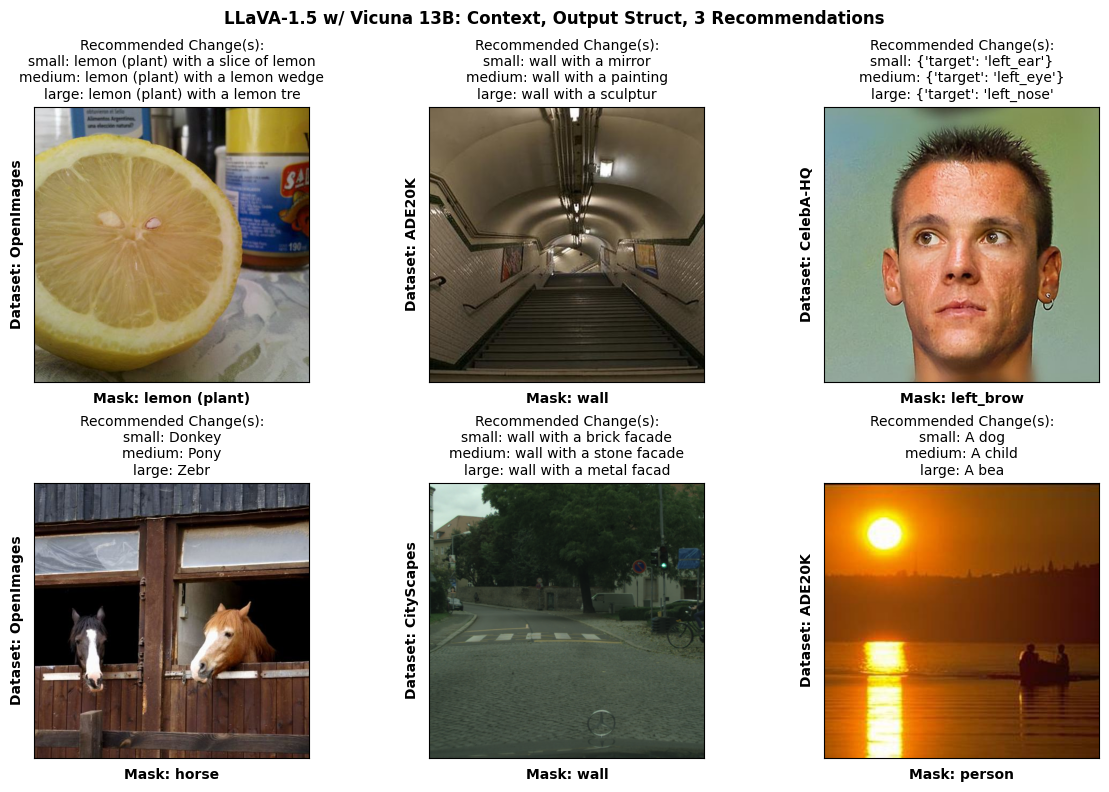

In [ ]:
title = "LLaVA-1.5 w/ Vicuna 13B: Context, Output Struct, 3 Recommendations"
visualize_images(data_samp, figsize=(12, 8), suptitle=title)

## Context, 1 Recommendations based on STR Input:

In [ ]:
context = """
Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

1. Small Semantic Change: Involves subtle modifications to the image but don't drastically alter its overall meaning.
2. Medium Semantic Change: Involves more noticeable alterations that can shift the focus or narrative of the image.
3. Large Semantic Change: Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image. It may even appear suprising or stange to an audience.

Using the definitions of small, medium, and large semantic changes above,"""

In [ ]:
def get_llava_perts(data_samp):
    """
    Uses the latest instantiation of the ``size_based_change`` function
    to generate recommended perturbations for a set of images using LLaVA.

    The recommended perturbation is saved in the ``data_samp`` dictionary,
    under the key ``target``.
    """

    for id_, info in data_samp.items():

        mask = info["object"]["name"]
        image_file = os.path.join(ROOT_DIR, info["image_path"])
        try:
            output = size_based_change(image_file, mask)
            mag_change = None
        except:
            mag_change = random.choice(["small", "medium", "large"])
            output = size_based_change(image_file, mask, mag_change)

        if '{' in output:
            structured = False
            while not structured:
                try:
                    target = clean_json_output(output)
                    structured = True
                except:
                    continue

            target_str = ""
            for k, v in target.items():
                target_str += f"{k}: {v}\n"
            output = target_str[:-2]

        elif mag_change is not None:
            output = f"Magnitude: {mag_change} semantic change\n{output}"

        info["object"]["target"] = output
        data_samp[id_] = info

    return data_samp


def size_based_change(img_path, mask, mag_change, aug_p=0.5):

    prompt_types = ["aug", "replace"]
    type_ = random.choice(prompt_types)
    print(type_)
    ### augmentation prompt
    if type_ == "aug":
        prompt = f"{context} what augmentation can I make to {mask} in the image that would produce a {mag_change} semantic change? The change must be of a similar size and structure to the {mask}. Represent the recommended change with a preposition, as in '{mask} with X', or with an adjective, as in 'X {mask}'. Do not include explanation and use as few words as possible."

    ### change prompt
    else:
        prompt = f"{context} what is something of a similar size and structure to the {mask} that I can replace the {mask} with to produce a {mag_change} semantic change in the image? Return only the target object. Do not include explanation and  as few words as possible."

    setattr(args,"query",prompt )
    setattr(args,"image_file", img_path)

    return eval_model_wo_loading(tokenizer, model, image_processor, context_len, args)

In [ ]:
# getting llava recommended changes:
data_samp_processed = get_llava_perts(data_samp)

replace
replace
aug
replace
aug
replace


<ipython-input-17-f3d214da4c6b>:66: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


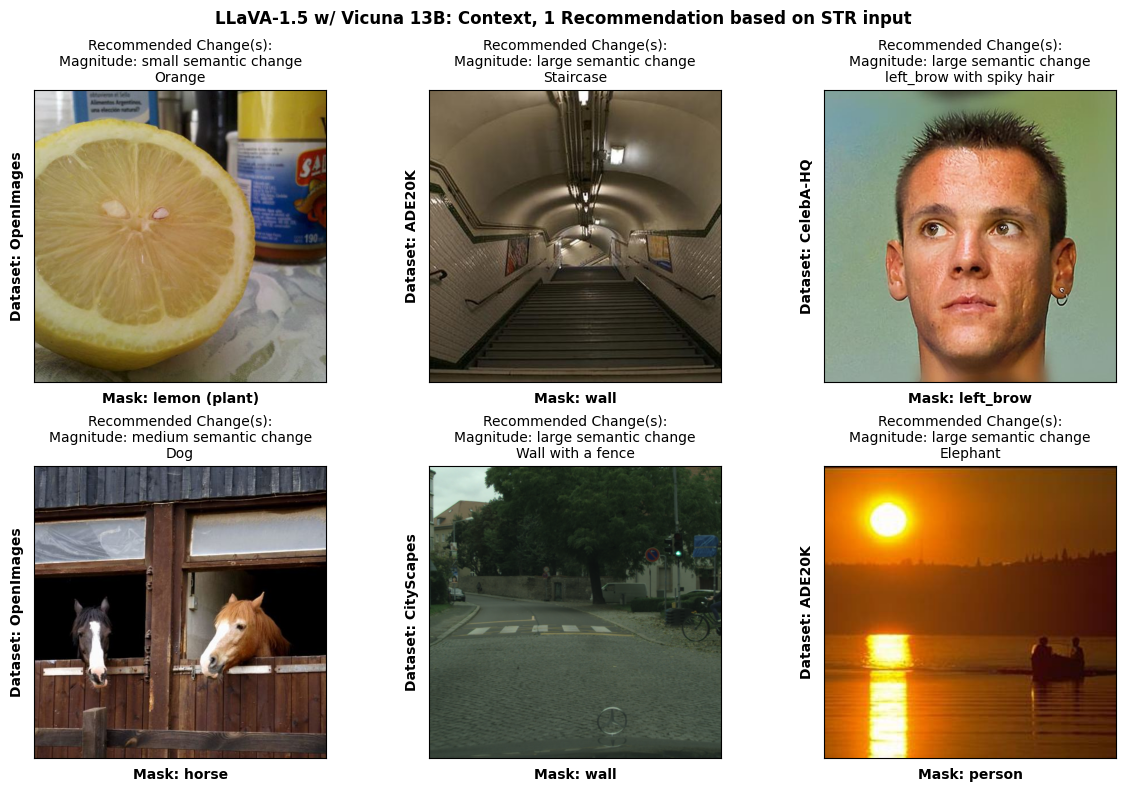

In [ ]:
title = "LLaVA-1.5 w/ Vicuna 13B: Context, 1 Recommendation based on STR input"
visualize_images(data_samp, figsize=(12, 8), suptitle=title)

# Prompt Sandox

In this section we explore creating effective prompts for each architecture. The goal is to structure the text to be as close to the training distribution as possible.

**Idea:** Query each model for how they would describe small, medium, and large semantic change. Adjust the descriptions to fit our needs/expectations. Provide that are the context 'taxonomy' for inference.

## Mistral-7B

**Question-1:** How would you describe a small, medium and large semantic change to an image?


**Output:** A small semantic change to an image could be something like changing the color of a specific object or person within the image, or perhaps adding or removing a minor detail. This change would not significantly alter the overall meaning or context of the image.

A medium semantic change to an image could involve adjusting the composition or perspective of the image, perhaps by moving an object or person to a different location within the frame, or by changing the angle or distance from which the image is viewed. This change could slightly alter the way the viewer perceives the image and its subject matter.

A large semantic change to an image would involve making significant alterations to the image's content or meaning. This could include adding or removing major elements of the image, such as people, objects, or landmarks, or making fundamental changes to the image's color scheme, lighting, or other visual elements. This type of change would significantly alter the overall meaning and context of the image, and could potentially change its intended message or meaning entirely.

**Question-2:** What kinds of changes to an image would cause a small, medium, and large semantic change?


**Output:** A semantic change in an image refers to a change in its meaning or interpretation. The size of the change can be classified as small, medium, or large based on the extent of the difference in meaning. Here are some examples of changes that could cause a small, medium, or large semantic change in an image:

Small semantic change:
* Changing the color of an object in the image
* Adding or removing a small detail in the image
* Adjusting the brightness or contrast of the image
* Changing the perspective or angle of the image

Medium semantic change:
* Removing a major object or character from the image
* Adding a new object or character to the image that significantly changes the scene
* Changing the lighting conditions in the image
* Adding or removing a background element that affects the overall mood of the image

Large semantic change:
* Changing the subject or main focus of the image
* Adding or removing a major element that completely changes the meaning of the image
* Changing the composition or arrangement of objects in the image
* Adding or removing a significant amount of detail that affects the overall interpretation of the image.

## Chat-GPT (3.5)

**Question-1:** How would you describe a small, medium and large semantic change to an image?


**Output:** Semantic change in images refers to alterations in meaning or interpretation. Here's how you might describe small, medium, and large semantic changes to an image:

Small Semantic Change:
* Involves subtle modifications that may affect the perception or interpretation of the image but don't drastically alter its overall meaning.
* Example: Adjusting the lighting or color balance slightly to evoke a different mood or atmosphere. This might involve warming or cooling the colors, or slightly increasing the contrast.

Medium Semantic Change:
* Involves more noticeable alterations that can shift the focus or narrative of the image.
* Example: Adding or removing key elements within the image that significantly impact its meaning or story. This could involve adding a person to the background or removing an object that distracts from the main subject.

Large Semantic Change:
* Involves substantial modifications that fundamentally transform the interpretation or message conveyed by the image.
* Example: Completely replacing the background scenery or context of the image. For instance, changing a serene natural landscape into an urban cityscape or vice versa. This can completely change the emotional tone or narrative of the image.
In essence, small changes may be subtle tweaks to enhance the existing meaning, medium changes alter the focus or narrative to some extent, and large changes completely overhaul the interpretation or message conveyed by the image.

**Question-2:** What kinds of changes to an image would cause a small, medium, and large semantic change?



**Output:** Certainly! Let's delve deeper into specific changes that could cause small, medium, and large semantic shifts in an image:

Small Semantic Change:
* Color Adjustments: Slight alterations in color temperature, saturation, or hue can subtly influence the mood or tone of an image without drastically changing its meaning.
* Contrast Tweaks: Adjusting contrast slightly can enhance certain details or make the image pop more, subtly impacting its interpretation.
* Brightness/Exposure: Fine-tuning brightness or exposure levels can subtly affect the perceived lighting conditions in the image, influencing its mood.
* Sharpness/Blur: Minor adjustments to the sharpness or blur levels can draw attention to specific areas of the image, subtly shifting its focus.

Medium Semantic Change:
* Object Additions/Removals: Adding or removing objects or elements within the image that are not central to its composition can change the context or narrative of the scene.
* Background Alterations: Changing the background scenery or context of the image can shift its narrative or setting, influencing the viewer's interpretation.
* Cropping: Adjusting the cropping of the image to include or exclude certain elements can change the composition and focus of the image, altering its meaning.
* Filter Effects: Applying different filter effects or styles can change the overall aesthetic and emotional tone of the image, impacting its interpretation.

Large Semantic Change:
* Object Replacement: Completely replacing key objects or elements within the image with different ones can drastically alter its narrative, context, or meaning.
* Scene Transformation: Changing the entire scene or setting of the image, such as transforming a rural landscape into a futuristic cityscape, can completely change its interpretation and message.
* Composite Imagery: Combining multiple images or elements to create a new composite image with a different narrative or context can result in a significant semantic shift.
* Genre Conversion: Converting the image from one genre to another, such as turning a realistic photograph into a surreal digital art piece, can completely change its interpretation and meaning.

These examples illustrate how different types of changes can lead to varying degrees of semantic shifts in an image, ranging from subtle adjustments to complete transformations.

## Vicuna-13B

**Question-1:** How would you describe a small, medium and large semantic change to an image?


**Output:** A small semantic change to an image might involve a subtle alteration to a single element within the image, such as changing the color of an object or adding a small detail to the scene.

A medium semantic change might involve a more significant alteration to the image, such as adding or removing a larger object or changing the overall lighting and color scheme.

A large semantic change would involve a complete transformation of the image, such as changing the subject or background, or altering the composition and perspective of the scene.

**Question-2:** What kinds of changes to an image would cause a small, medium, and large semantic change?


**Output:** *Gave the same answer as above..*

## GPT-4 (preview-0125)

**Question:** How would you describe a small, medium and large semantic change to an image?


**Output:** Semantic changes to an image involve alterations that modify the meaning or context of the image without necessarily changing its basic appearance drastically. These changes can range from subtle to significant. Here's how you might describe small, medium, and large semantic changes:

**Small Semantic Change**

A small semantic change involves a minor modification that slightly alters the meaning or context of the image. This could include adding or altering a small object in the background, changing a facial expression slightly, or modifying the color of a less significant element. For example, changing the expression of a person in a group photo from neutral to slightly smiling might subtly change the perceived mood of the image without affecting its overall composition or theme.

**Medium Semantic Change**

Medium semantic changes are more noticeable and have a greater impact on the image's meaning or context. This could involve replacing one key element with another, significantly altering the background to change the setting, or modifying the attire of a person to suggest a different activity or status. For example, changing the background of a portrait from an office interior to a beach setting alters the context and possibly the narrative behind the image, though the main subject remains the same.

**Large Semantic Change**

Large semantic changes fundamentally transform the meaning, context, or narrative of an image. This could involve combining elements from multiple images to create a new scene, significantly altering the actions or interactions between subjects within the image, or changing the time of day or weather conditions to convey a completely different mood or story. For example, editing an image to change a peaceful street scene into a chaotic one with the addition of elements like crowds, protest signs, or police significantly alters the semantic content and the message of the image.

In essence, the size of a semantic change is determined by how much the meaning or context of the image is altered, ranging from subtle adjustments to complete transformations.